# Modeling single-cell proximity data from chromatin tracing experiments

#### A tutorial in using the `topic3d` software package

## Background

In this tutorial, we will
- load some in pairwise proximity data and visualize it
- train an LDA model on this data and evaluate the model's quality
- visualize the results of the modeling

Importing required modules

In [1]:
import subprocess
import joblib
import h5py

import numpy as np

import matplotlib.pyplot as plt

from scipy.spatial.distance import squareform
from topic3d.datatypes import PWProxArrayStack
from topic3d.results import Topic3DResult
from IPython.display import Image

### Visualizing the sample data

In [2]:
data = PWProxArrayStack(np.load("./data/sample_exp.npy"))
data.shape

(1745, 946)

Plotting random examples from this ensemble shows us the diversity in individual (read, "single-cell") maps. Our goal is to use LDA to decompose this data based on patterns in proximity co-occurrence. Since the red pixels indicate the regions in proximity, LDA simply needs to find patterns in pixel co-occurrence. 

/tmp/ipykernel_1523587/85617236.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


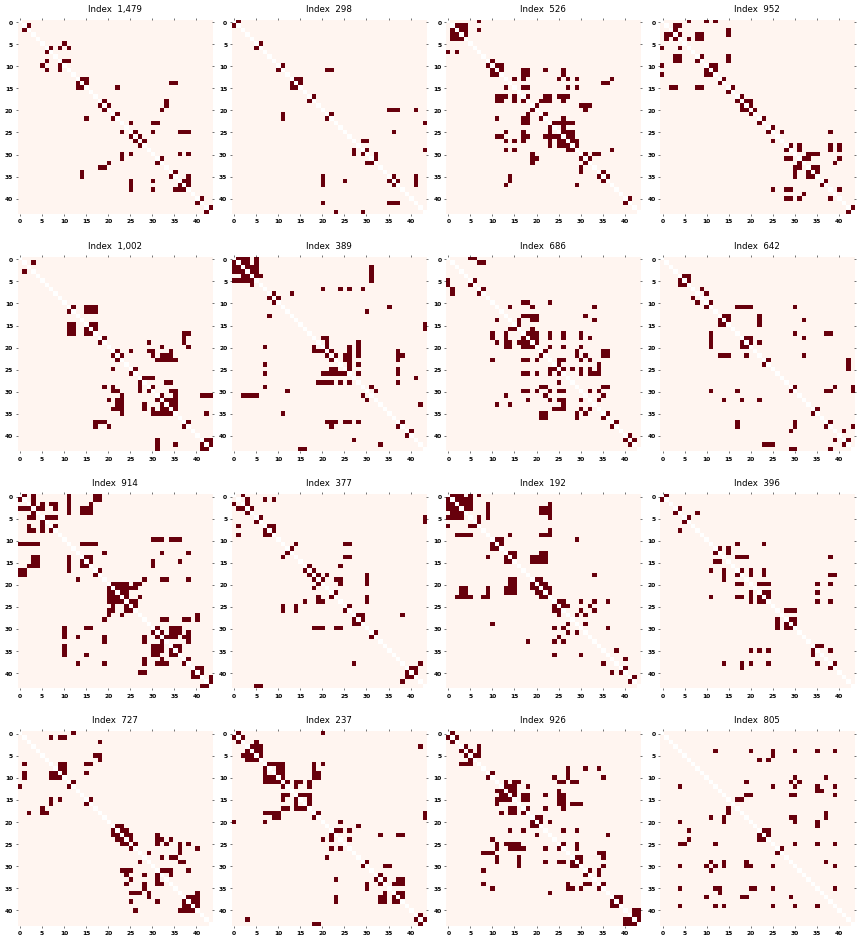

In [3]:
fig = data.plot_random_examples(num_items=16,
                                random_seed=None,
                                form="square",
                                include_cbar=False)
fig.set_dpi(48)
fig.show()

/tmp/ipykernel_1523587/821489727.py:3: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


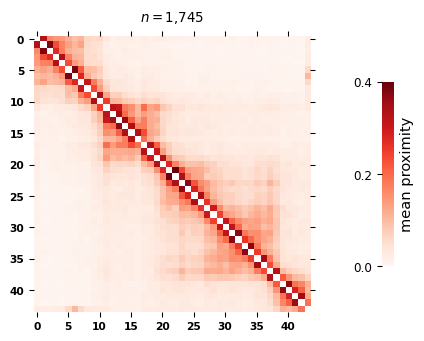

In [4]:
fig = data.plot_ensemble_measure(method="mean", form="square", cbar_label="mean proximity")
fig.set_dpi(96)
fig.show()

### Model training and dataset decomposition

In [34]:
!topic3d runall \
    --data_train_file "./data/sample_exp.npy" \
    --model_file "./models/model_exp.jl" \
    --results_dir "./results/###" \
    --num_CFMs 15 \
    --max_iter 100 \
    --evaluate_learning
    # --params_file "./parameters.json" \

{'data_train_file': './data/sample_exp.npy', 'data_test_file': None, 'model_file': './models/model_exp.jl', 'results_dir': './results/###', 'params_file': None, 'num_CFMs': 15, 'max_iter': 100, 'random_state': None, 'learning_method': 'batch', 'batch_size': 128, 'evaluate_learning': True, 'assess_model_quality': False}
(1745, 946) int64
2026-03-18 22:56:14,903 [INFO] --------------------------------------------------
2026-03-18 22:56:14,903 [INFO] [c8aaf4] Will save run outputs to: ./results/c8aaf4
2026-03-18 22:56:14,903 [INFO] Settings summary for run: c8aaf4
2026-03-18 22:56:14,903 [INFO]     data_train_file: ./data/sample_exp.npy
2026-03-18 22:56:14,903 [INFO]     data_test_file: None
2026-03-18 22:56:14,903 [INFO]     model_file: ./models/model_exp.jl
2026-03-18 22:56:14,903 [INFO]     results_dir: ./results/###
2026-03-18 22:56:14,903 [INFO]     params_file: None
2026-03-18 22:56:14,903 [INFO]     num_CFMs: 15
2026-03-18 22:56:14,903 [INFO]     max_iter: 100
2026-03-18 22:56:14,9